# Práctica 3 — Detección y reconocimiento de formas

Paquetes necesarios

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import csv
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

---
## TAREA 1: Contar dinero

Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia implicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

**IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo**

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

### 1.1 Datos de referencia y funciones auxiliares

Solo se usan las técnicas vistas en los ejemplos del cuaderno:

1. **Segmentación**: suavizado Gaussiano y umbralizado binario invertido (Otsu por defecto, o un umbral fijo). Las monedas quedan en blanco sobre fondo negro. Se umbraliza el **canal azul** en lugar del gris: las monedas doradas y cobrizas tienen muy poco azul, y con poca luz en gris se confunden con el fondo.
2. **Contornos externos** con `findContours(RETR_EXTERNAL)`. Para cada contorno se calculan, como en el ejemplo de formas:
   - área (`contourArea`) para descartar ruido,
   - **compacidad** `P²/A` (`arcLength`, `contourArea`): un círculo da 4π ≈ 12.6,
   - **relación entre ejes de la elipse ajustada** (`fitEllipse`): un círculo da 1.

   Si ambas son próximas a las de un círculo el contorno es una moneda. Su radio es el **semieje menor** de la elipse: la sombra alarga la moneda solo en la dirección de la luz, y el eje perpendicular sigue midiendo el diámetro real. El resto se consideran *otros objetos* (o monedas solapadas). Los contornos que tocan el borde de la imagen (`boundingRect`) se descartan, porque la moneda está cortada.
3. **Calibración**: el usuario hace clic en la moneda de 1€ → `px_por_mm = 2·r / 23.25`.
4. **Clasificación por tamaño**: cada diámetro se pasa a mm y se asigna la moneda con el diámetro oficial más cercano, rechazando si la diferencia supera `TOL_MM`. Además se usa el **color**: con la media de los canales verde y rojo dentro de la moneda se distingue el cobre (1c, 2c, 5c; G/R ≈ 0.60-0.70, rojizo) del dorado y las bimetálicas (G/R ≥ 0.75), y solo se compara con las monedas de ese grupo. Así no se confunden monedas de tamaño parecido y distinto material, como el 5c (21.25 mm) y el 20c (22.25 mm).
5. Como alternativa (útil con monedas solapadas) se ofrece la **Transformada de Hough** (`HoughCircles` tras `medianBlur`).

In [11]:
# Valor en euros -> diámetro oficial en mm
MONEDAS = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75,
}
COBRE = {0.01, 0.02, 0.05}  # monedas de cobre; el resto son doradas o bimetálicas

DIAM_REFERENCIA_MM = MONEDAS[1.00]  # moneda usada para calibrar
TOL_MM = 0.7         # diferencia máxima admitida con el diámetro oficial (webcam: 1 px ~ 0.15 mm)
AREA_MIN = 500       # área mínima en píxeles para descartar ruido
COMPACIDAD_MAX = 18  # P^2/A: un círculo perfecto da 4*pi = 12.6
ELIPSE_MAX = 1.2     # relación entre ejes de la elipse ajustada (círculo = 1)
VERDE_ROJO_COBRE = 0.73  # G/R máximo del cobre: cobre ~0.60-0.70, dorado/bimetálica >= 0.75


def umbralizar(img_bgr, fondo_claro=True, umbral=0, canal_azul=True):
    """Suavizado + umbralizado. Con umbral=0 se usa Otsu.
    Por defecto se umbraliza el canal azul en lugar del gris: las monedas doradas y
    cobrizas tienen muy poco azul, así que destacan aunque en gris se parezcan al fondo.
    Las monedas quedan en blanco sobre fondo negro."""
    if canal_azul:
        gris = img_bgr[:, :, 0]  # OpenCV guarda la imagen en BGR: canal 0 = azul
    else:
        gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    tipo = cv2.THRESH_BINARY_INV if fondo_claro else cv2.THRESH_BINARY
    if umbral == 0:
        tipo += cv2.THRESH_OTSU
    th, img_th = cv2.threshold(gris, umbral, 255, tipo)
    return th, img_th


def detectar_monedas(img_th, area_min=AREA_MIN):
    """Busca contornos externos y separa los que parecen monedas del resto.
    monedas: lista de (x, y, r) con el centro y radio de la elipse ajustada.
    otros:   contornos no circulares (objetos que no son monedas o monedas solapadas)
             y contornos cortados por el borde de la imagen."""
    alto, ancho = img_th.shape[:2]
    contornos, _ = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    monedas, otros = [], []
    for c in contornos:
        area = cv2.contourArea(c)
        if area < area_min or len(c) < 5:
            continue
        # Si toca el borde la moneda está cortada y su tamaño no es fiable
        x, y, w, h = cv2.boundingRect(c)
        if x <= 1 or y <= 1 or x + w >= ancho - 1 or y + h >= alto - 1:
            otros.append(c)
            continue
        perimetro = cv2.arcLength(c, True)
        compacidad = perimetro ** 2 / area
        (cx, cy), ejes, _ = cv2.fitEllipse(c)
        elipse_ratio = max(ejes) / min(ejes)
        if compacidad <= COMPACIDAD_MAX and elipse_ratio <= ELIPSE_MAX:
            # La sombra alarga la moneda solo en la dirección de la luz: el eje menor
            # (perpendicular a la sombra) mide el diámetro real
            r = min(ejes) / 2
            monedas.append((cx, cy, r))
        else:
            otros.append(c)
    return monedas, otros


def circulo_en_punto(circulos, px, py):
    """Devuelve el círculo que contiene el punto (px, py), o None."""
    for (x, y, r) in circulos:
        if (px - x) ** 2 + (py - y) ** 2 <= r ** 2:
            return (x, y, r)
    return None


def es_cobre(img_bgr, x, y, r):
    """True si la moneda es de cobre (1c, 2c, 5c): el cobre es rojizo, con mucho menos
    verde que rojo, mientras que en las doradas y bimetálicas el verde y el rojo se parecen."""
    mascara = np.zeros(img_bgr.shape[:2], np.uint8)
    cv2.circle(mascara, (int(x), int(y)), int(0.8 * r), 255, -1)
    verde = img_bgr[:, :, 1][mascara > 0].mean()
    rojo = img_bgr[:, :, 2][mascara > 0].mean()
    return verde / rojo < VERDE_ROJO_COBRE


def clasificar_moneda(diam_mm, cobre=None):
    """Valor de la moneda con el diámetro oficial más cercano, o None si ninguna encaja.
    Si se conoce el color (cobre True/False) solo se compara con las monedas de ese grupo."""
    candidatas = [v for v in MONEDAS if cobre is None or (v in COBRE) == cobre]
    valor = min(candidatas, key=lambda v: abs(diam_mm - MONEDAS[v]))
    if abs(diam_mm - MONEDAS[valor]) > TOL_MM:
        return None
    return valor


def contar_dinero(circulos, px_por_mm, img_bgr=None):
    """Devuelve el total en euros y la lista de (circulo, valor, diam_mm).
    Si se pasa la imagen, el color de cada moneda (cobre o no) restringe su clasificación."""
    total = 0.0
    resultado = []
    for (x, y, r) in circulos:
        diam_mm = 2 * r / px_por_mm
        cobre = es_cobre(img_bgr, x, y, r) if img_bgr is not None else None
        valor = clasificar_moneda(diam_mm, cobre)
        resultado.append(((x, y, r), valor, diam_mm))
        if valor is not None:
            total += valor
    return total, resultado


def texto_valor(valor):
    return f'{valor:.0f} EUR' if valor >= 1 else f'{valor * 100:.0f} c'


def dibujar_resultado(img_bgr, resultado, total, otros=()):
    """Monedas reconocidas en verde con su valor y diámetro; no reconocidas y otros objetos en rojo."""
    salida = img_bgr.copy()
    font = cv2.FONT_HERSHEY_SIMPLEX
    for (x, y, r), valor, diam_mm in resultado:
        centro = (int(x), int(y))
        color = (0, 255, 0) if valor is not None else (0, 0, 255)
        cv2.circle(salida, centro, int(r), color, 2)
        texto = texto_valor(valor) if valor is not None else '?'
        cv2.putText(salida, texto, (centro[0] - 25, centro[1]), font, 0.7, (255, 0, 0), 2)
        cv2.putText(salida, f'{diam_mm:.1f}mm', (centro[0] - 25, centro[1] + 20), font, 0.5, (0, 0, 0), 1)
    cv2.drawContours(salida, list(otros), -1, (0, 0, 255), 2)
    cv2.putText(salida, f'Total: {total:.2f} EUR', (10, 30), font, 1, (0, 0, 0), 2)
    return salida

### 1.2 Imagen ideal con calibración por clic

Se abre una ventana de OpenCV: haz clic sobre la moneda de 1€ (ESC para cancelar). Si se quiere ejecutar sin interacción, basta con dar un punto en `PUNTO_REF`, p.ej. `(134, 347)`, que cae sobre el 1€ de `Monedas.jpg`.

Resultado esperado: 2€ + 1€ + 50c + 20c + 10c + 5c + 2c + 1c = **3.88 €**.

Umbral Otsu 180.0
Monedas detectadas: 8 | Otros objetos: 0
px/mm = 7.882322249873992
  ( 367, 815)  16.18 mm -> 1 c
  ( 142, 808)  22.63 mm -> 20 c
  ( 368, 587)  19.19 mm -> 2 c
  ( 140, 578)  24.54 mm -> 50 c
  ( 373, 355)  20.05 mm -> 10 c
  ( 134, 347)  23.25 mm -> 1 EUR
  ( 373, 118)  21.12 mm -> 5 c
  ( 130, 115)  25.99 mm -> 2 EUR
Total: 3.88 €


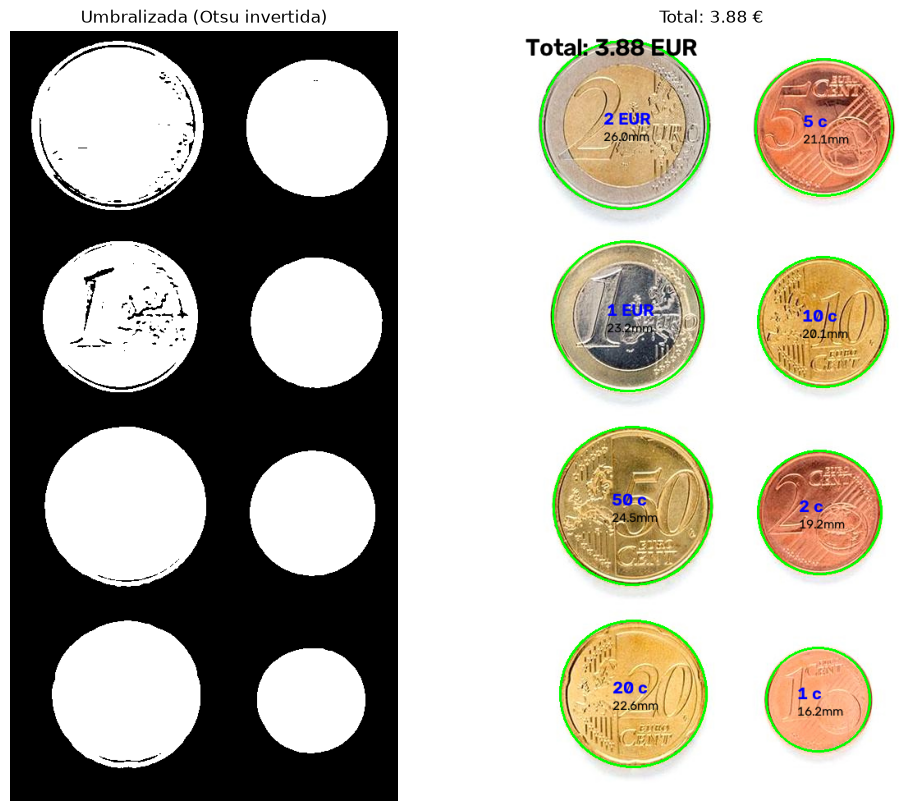

In [12]:
PUNTO_REF = None  # None -> calibración con clic; o un punto (x, y) sobre la moneda de 1€

img = cv2.imread('Monedas.jpg')
th, img_th = umbralizar(img)
print('Umbral Otsu', th)
monedas, otros = detectar_monedas(img_th)
print('Monedas detectadas:', len(monedas), '| Otros objetos:', len(otros))

# --- Calibración interactiva: clic sobre la moneda de 1€ ---
clic = [PUNTO_REF] if PUNTO_REF else []

def on_mouse(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clic.append((x, y))

if not clic:
    vista = img.copy()
    for (x, y, r) in monedas:
        cv2.circle(vista, (int(x), int(y)), int(r), (0, 255, 0), 2)
    cv2.putText(vista, 'Clic en la moneda de 1 EUR', (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    # KEEPRATIO evita que la ventana deforme la imagen; se escala para que quepa en pantalla
    cv2.namedWindow('Calibracion', cv2.WINDOW_NORMAL | cv2.WINDOW_KEEPRATIO)
    escala = min(1.0, 800 / img.shape[0])
    cv2.resizeWindow('Calibracion', int(img.shape[1] * escala), int(img.shape[0] * escala))
    cv2.setMouseCallback('Calibracion', on_mouse)
    while not clic:
        cv2.imshow('Calibracion', vista)
        if cv2.waitKey(20) == 27:  # ESC para salir
            break
    cv2.destroyAllWindows()

px_por_mm = None
if clic:
    ref = circulo_en_punto(monedas, *clic[0])
    if ref is None:
        print('El clic no cae sobre ninguna moneda detectada')
    else:
        px_por_mm = 2 * ref[2] / DIAM_REFERENCIA_MM

print('px/mm =', px_por_mm)

# --- Conteo ---
if px_por_mm:
    total, resultado = contar_dinero(monedas, px_por_mm, img)
    for (x, y, r), valor, diam in resultado:
        print(f'  ({x:4.0f},{y:4.0f})  {diam:5.2f} mm -> {texto_valor(valor) if valor else "?"}')
    print(f'Total: {total:.2f} €')

    plt.figure(figsize=(12, 10))
    plt.subplot(121)
    plt.axis('off')
    plt.imshow(img_th, cmap='gray')
    plt.title('Umbralizada (Otsu invertida)')
    plt.subplot(122)
    plt.axis('off')
    plt.imshow(cv2.cvtColor(dibujar_resultado(img, resultado, total, otros), cv2.COLOR_BGR2RGB))
    plt.title(f'Total: {total:.2f} €')
    plt.show()

### 1.3 Demostrador en vivo con cámara

Controles:
- **Clic** sobre la moneda de 1€ → calibra la escala.
- **r** → borra la calibración.
- **h** → alterna detección por contornos / Transformada de Hough.
- **o** → alterna umbral Otsu / umbral fijo; **+** / **-** ajustan el umbral fijo.
- **a** → alterna umbralizar el canal azul / la imagen en gris.
- **f** → alterna fondo claro / oscuro.
- **ESC** → salir.

Se muestra también la imagen umbralizada para comprobar la segmentación.

Recomendaciones: fondo liso y mate (un folio blanco va bien), luz difusa sin reflejos y cámara cenital y fija.

In [13]:
# Cámara del móvil con DroidCam por WiFi: se lee el vídeo directamente de la app del móvil.
# Hay que CERRAR el cliente DroidCam del PC, porque la app solo admite una conexión a la vez.
# La dirección es la que muestra la app en el móvil (puede cambiar al reconectar la WiFi).
FUENTE = 'http://192.168.1.50:4747/video'
# FUENTE = 0  # webcam del portátil
vid = cv2.VideoCapture(FUENTE)
ret, frame = vid.read()
if not ret:
    raise RuntimeError(f'No llega vídeo de {FUENTE}: ¿está la app abierta y el cliente del PC cerrado?')

estado = {'clic': None}
px_por_mm = None
fondo_claro = True
usar_hough = False
canal_azul = True  # umbraliza el canal azul (False -> gris)
umbral = 0        # 0 -> Otsu
umbral_fijo = 130

def on_mouse_vivo(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        estado['clic'] = (x, y)

def hough_monedas(frame, px_por_mm):
    """Círculos con la Transformada de Hough. Tras calibrar, el rango de radios
    se limita al de las monedas (de 1c a 2€)."""
    pimg = cv2.medianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 7)
    if px_por_mm:
        rmin = int(0.9 * MONEDAS[0.01] / 2 * px_por_mm)
        rmax = int(1.1 * MONEDAS[2.00] / 2 * px_por_mm)
    else:
        rmin, rmax = 20, 150
    circ = cv2.HoughCircles(pimg, cv2.HOUGH_GRADIENT, 1, 2 * rmin,
                            param1=100, param2=50, minRadius=rmin, maxRadius=rmax)
    return [] if circ is None else [tuple(c) for c in circ[0]]

cv2.namedWindow('Monedas')
cv2.setMouseCallback('Monedas', on_mouse_vivo)

while True:
    ret, frame = vid.read()
    if not ret:
        break

    th, img_th = umbralizar(frame, fondo_claro, umbral, canal_azul)
    if usar_hough:
        monedas, otros = hough_monedas(frame, px_por_mm), []
    else:
        monedas, otros = detectar_monedas(img_th, area_min=300)

    # Calibración con el clic sobre la moneda de 1€
    if estado['clic'] is not None:
        ref = circulo_en_punto(monedas, *estado['clic'])
        estado['clic'] = None
        if ref is not None:
            px_por_mm = 2 * ref[2] / DIAM_REFERENCIA_MM
            print(f'Calibrado: {px_por_mm:.2f} px/mm')

    if px_por_mm:
        total, resultado = contar_dinero(monedas, px_por_mm, frame)
        salida = dibujar_resultado(frame, resultado, total, otros)
    else:
        salida = frame.copy()
        for (x, y, r) in monedas:
            cv2.circle(salida, (int(x), int(y)), int(r), (0, 255, 255), 2)
        cv2.drawContours(salida, otros, -1, (0, 0, 255), 2)
        cv2.putText(salida, 'Haz clic en una moneda de 1 EUR', (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

    estado_txt = (f'{"Hough" if usar_hough else "contornos"}  '
                  f'{"azul" if canal_azul else "gris"} umbral:{"Otsu" if umbral == 0 else "fijo"}={th:.0f}  '
                  f'fondo:{"claro" if fondo_claro else "oscuro"}')
    cv2.putText(salida, estado_txt, (10, salida.shape[0] - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    cv2.imshow('Monedas', salida)
    cv2.imshow('Umbralizada', img_th)

    tecla = cv2.waitKey(20) & 0xFF
    if tecla == 27:
        break
    elif tecla == ord('r'):
        px_por_mm = None
    elif tecla == ord('h'):
        usar_hough = not usar_hough
    elif tecla == ord('o'):
        umbral = umbral_fijo if umbral == 0 else 0
    elif tecla == ord('+'):
        umbral_fijo = min(254, umbral_fijo + 5)
        umbral = umbral_fijo
    elif tecla == ord('-'):
        umbral_fijo = max(1, umbral_fijo - 5)
        umbral = umbral_fijo
    elif tecla == ord('a'):
        canal_azul = not canal_azul
    elif tecla == ord('f'):
        fondo_claro = not fondo_claro

vid.release()
cv2.destroyAllWindows()

Calibrado: 7.25 px/mm


**Conclusiones Tarea 1**

*Imagen ideal*: con Otsu se obtienen los 8 contornos, todos con compacidad ≈ 14 y relación de ejes ≈ 1. Calibrando con el 1€ las ocho monedas se clasifican bien y el total es **3.88 €**. El radio se toma de la elipse ajustada, que resultó más preciso que el de `minEnclosingCircle` (sobreestima con cualquier irregularidad del borde) y que el de `HoughCircles` (daba 87 px para el 1€ frente a 93 px). Hay monedas que solo difieren 1 mm (1€ 23.25 / 50c 24.25 / 20c 22.25), por lo que un error de pocos píxeles en el radio basta para confundirlas.

*Demostrador en vivo*: en una primera prueba con poca luz, el umbral sobre el gris (Otsu = 54) no separaba las monedas claras del fondo: solo se segmentaba su **sombra** (una media luna, que se descartaba por compacidad), y en las oscuras la sombra se pegaba al contorno y agrandaba el diámetro. Se corrigió umbralizando el canal azul (las 6 monedas segmentadas), usando el eje menor de la elipse como diámetro y descartando las monedas cortadas por el borde. Tras calibrar con el 1€, el resto de diámetros quedan a menos de 0.6 mm del oficial, por lo que con la webcam la tolerancia se subió a 0.7 mm (1 px ≈ 0.15 mm).

Limitaciones:
- **Iluminación**: el umbral global falla con luz no uniforme, y los reflejos rompen el contorno (se vuelve menos compacto o más pequeño). Las **sombras** se pegan a la moneda y aumentan su diámetro.
- **Escala y perspectiva**: la relación px/mm solo es válida a la distancia a la que se calibró. Además, si la cámara no está paralela a la mesa, las monedas más cercanas a ella se ven más grandes. En una prueba con la cámara algo inclinada la escala variaba de 6.46 a 6.85 px/mm de una esquina a otra (un 6 %, unos 1.3 mm en una moneda de 22 mm): un 20c en la esquina cercana medía 23.2 mm y se clasificaba como 1€. Con la cámara paralela a la mesa desaparece el problema.
- **Otros objetos**: los no circulares se rechazan por compacidad y relación de ejes, y los circulares de tamaño ajeno por la tolerancia, pero un objeto redondo de tamaño parecido a una moneda se contaría.
- **Solape**: dos monedas que se tocan forman un único contorno no circular y se descartan (en rojo). Con la Transformada de Hough (tecla *h*) sí pueden detectarse por separado, aunque es más sensible a los parámetros y no distingue objetos que no son monedas.

---
## TAREA 2: Clasificación de microplásticos

La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

**IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo**

Recordatorio: *MPs_test.jpg* solo se usa para evaluar, nunca para entrenar. Entrenamiento: las imágenes completas *fragment-03-olympus-10-01-2020.JPG*, *pellet-03-olympus-10-01-2020.JPG* y *tar-03-olympus-10-01-2020.JPG*.

### 2.1 Segmentación y extracción de características

Las imágenes de entrenamiento son las tres **imágenes completas** (fotos de 4608×3456 con una sola clase cada una), no las subimágenes `FRA.png`, `PEL.png` y `TAR.png`, que solo tienen unas 10 partículas. Se reducen a ¼ para trabajar con partículas de tamaño parecido al del test.

**Segmentación.** El umbral global sobre el gris (fijo u Otsu) falla aquí por dos razones: el fondo no es uniforme (viñeteado en las fotos, bandas horizontales en el escáner del test) y hay partículas **más claras** que el fondo (fragmentos blancos) y otras **más oscuras** (alquitrán). La idea es la del **umbralizado adaptativo** del cuaderno: comparar cada píxel con su entorno en vez de con un valor único para toda la imagen.
1. Se estima el **fondo** con `medianBlur` de 51×51: la mediana de una ventana mucho mayor que las partículas las borra y deja solo el fondo.
2. Se resta el fondo a la imagen (**diferencia absoluta**, en el canal donde sea mayor), así se detectan tanto las partículas claras como las oscuras o de color. Se probó `adaptiveThreshold` (claras y oscuras por separado), pero usa la media de la ventana y solo el gris, y en el test dejaba 36 partículas sin detectar.
3. Se suaviza con `GaussianBlur` y se **umbraliza con un umbral fijo**. Otsu daba un umbral demasiado alto (lo dominan las partículas oscuras y se pierden las blancas). El valor 12 se eligió con las imágenes de entrenamiento, para que el número de partículas coincida con el indicado en el README (≈80 FRA, ≈55 PEL, ≈54 TAR).
4. Contornos externos y filtro por **área mínima** para descartar el ruido (la heurística de tamaño que propone el README).

**Características** (las de SMACC, más una de apariencia):
- área y perímetro (solo informativas: la escala del test es distinta, así que no se usan para clasificar),
- compacidad P²/A (círculo = 12.6),
- área / área del contenedor y ancho / alto del contenedor (se usa el contenedor de área mínima, `minAreaRect`, para que no dependa de la orientación),
- relación entre ejes de la elipse ajustada (menor / mayor),
- relación entre la distancia mínima y máxima del centroide (momentos) al contorno,
- **oscuridad relativa**: mediana del gris de la partícula dividida por la mediana del fondo estimado en esa zona. Se usa la mediana y no la media para que no influyan los brillos ni el borde de fondo que queda dentro del contorno.

In [14]:
CLASES = ['FRA', 'PEL', 'TAR']
IMAGENES_ENTRENAMIENTO = {
    'FRA': 'fragment-03-olympus-10-01-2020.JPG',
    'PEL': 'pellet-03-olympus-10-01-2020.JPG',
    'TAR': 'tar-03-olympus-10-01-2020.JPG',
}
ESCALA_ENTRENAMIENTO = 0.25  # las fotos de entrenamiento se reducen a 1/4
K_FONDO = 51                 # ventana de la mediana que estima el fondo (mucho mayor que las partículas)
UMBRAL_DIF = 12              # diferencia mínima con el fondo (elegido con las imágenes de entrenamiento)
AREA_MIN_MP = 30             # área mínima de una partícula en píxeles (descarta el ruido)

NOMBRES_CARACT = ['area', 'perimetro', 'compacidad', 'area/contenedor', 'ancho/alto',
                  'ejes elipse', 'dist centroide', 'oscuridad']
IDX = {n: i for i, n in enumerate(NOMBRES_CARACT)}


def segmentar(img_bgr):
    """Devuelve los contornos externos de las partículas y la imagen del fondo estimado."""
    fondo = cv2.medianBlur(img_bgr, K_FONDO)
    # Máxima diferencia por canal con el fondo: detecta partículas claras, oscuras y de color
    dif = cv2.absdiff(img_bgr, fondo).max(axis=2)
    dif = cv2.GaussianBlur(dif, (5, 5), 0)
    _, mask = cv2.threshold(dif, UMBRAL_DIF, 255, cv2.THRESH_BINARY)
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # El área mínima descarta el ruido; fitEllipse necesita al menos 5 puntos
    return [c for c in contornos if cv2.contourArea(c) >= AREA_MIN_MP and len(c) >= 5], fondo


def extraer_caracteristicas(c, gris, gris_fondo):
    """Devuelve un vector (np.array) de características de un contorno (orden de NOMBRES_CARACT)."""
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    compacidad = perimetro ** 2 / area

    # Contenedor de área mínima (girado): no depende de la orientación de la partícula
    _, (w, h), _ = cv2.minAreaRect(c)
    rel_area_contenedor = area / (w * h)
    rel_ancho_alto = min(w, h) / max(w, h)

    _, ejes, _ = cv2.fitEllipse(c)
    rel_ejes_elipse = min(ejes) / max(ejes)

    # Centroide con los momentos y relación entre la distancia mínima y máxima al contorno
    M = cv2.moments(c)
    cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    dist = np.sqrt((c[:, 0, 0] - cx) ** 2 + (c[:, 0, 1] - cy) ** 2)
    rel_dist_centroide = dist.min() / dist.max()

    # Oscuridad: gris de la partícula dividido por el gris del fondo en esa zona.
    # Se usa la mediana (no la media) para que no influyan los brillos ni el borde
    mascara = np.zeros(gris.shape, np.uint8)
    cv2.drawContours(mascara, [c], -1, 255, -1)  # contorno relleno
    dentro = mascara > 0
    oscuridad = np.median(gris[dentro]) / np.median(gris_fondo[dentro])

    return np.array([area, perimetro, compacidad, rel_area_contenedor, rel_ancho_alto,
                     rel_ejes_elipse, rel_dist_centroide, oscuridad])


def procesar_imagen(img_bgr):
    """Segmenta la imagen y devuelve (contornos, matriz de características)."""
    contornos, fondo = segmentar(img_bgr)
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris_fondo = cv2.cvtColor(fondo, cv2.COLOR_BGR2GRAY)
    feats = np.array([extraer_caracteristicas(c, gris, gris_fondo) for c in contornos])
    return contornos, feats

### 2.2 "Entrenamiento" con las imágenes completas de FRA, PEL y TAR

Cada imagen contiene una sola clase, así que todas sus partículas quedan etiquetadas con ella. Se muestra la segmentación para validarla y la distribución de cada característica por clase, para ver cuáles separan mejor las clases.

FRA partículas: 71
PEL partículas: 55
TAR partículas: 54


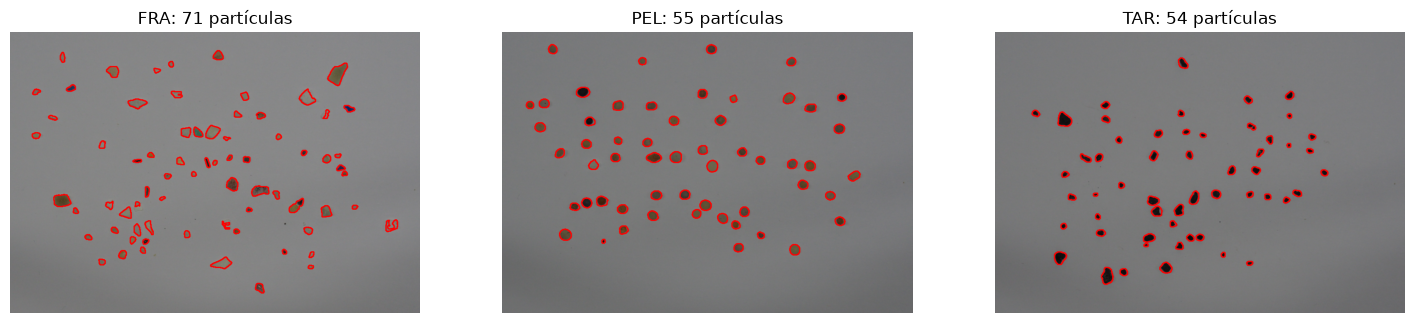

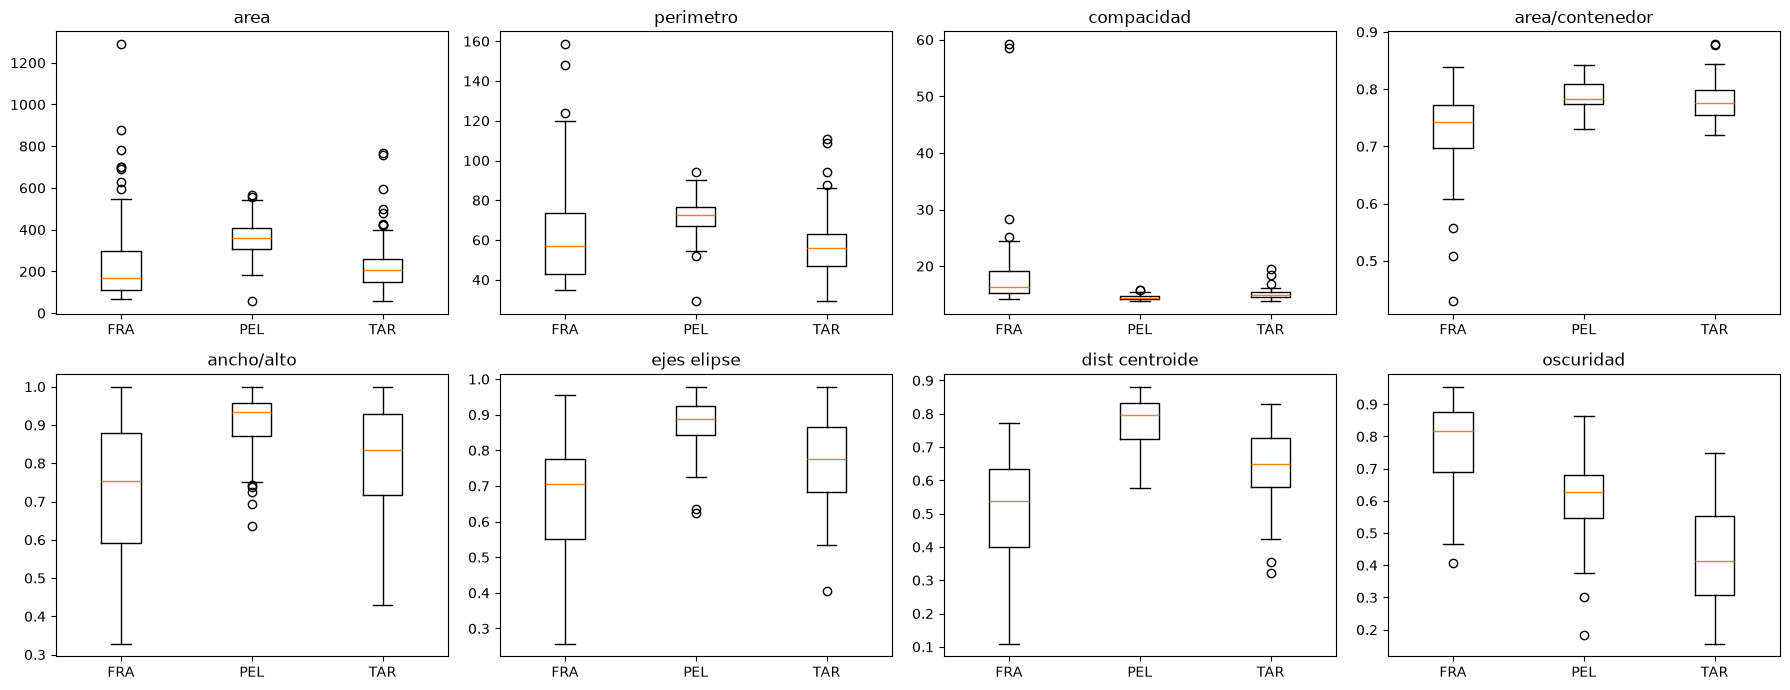

                             FRA             PEL             TAR
area               170.50 ±225.28   361.00 ±96.37   208.00 ±153.47
perimetro           56.97 ±27.85    72.53 ±10.54    55.87 ±17.90
compacidad          16.36 ± 7.43    14.39 ± 0.44    14.91 ± 0.98
area/contenedor      0.74 ± 0.07     0.78 ± 0.02     0.78 ± 0.03
ancho/alto           0.75 ± 0.18     0.93 ± 0.08     0.83 ± 0.13
ejes elipse          0.71 ± 0.16     0.89 ± 0.07     0.78 ± 0.12
dist centroide       0.54 ± 0.15     0.80 ± 0.07     0.65 ± 0.11
oscuridad            0.82 ± 0.13     0.63 ± 0.12     0.41 ± 0.15


In [15]:
datos = {}  # clase -> matriz (n_particulas x n_caract)
plt.figure(figsize=(18, 5))
for i, clase in enumerate(CLASES):
    img = cv2.imread(IMAGENES_ENTRENAMIENTO[clase])
    img = cv2.resize(img, None, fx=ESCALA_ENTRENAMIENTO, fy=ESCALA_ENTRENAMIENTO,
                     interpolation=cv2.INTER_AREA)
    contornos, datos[clase] = procesar_imagen(img)
    print(clase, 'partículas:', len(contornos))

    vista = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    cv2.drawContours(vista, contornos, -1, (255, 0, 0), 2)
    plt.subplot(1, 3, i + 1)
    plt.axis('off')
    plt.imshow(vista[50:700, 150:1100])  # zona central, donde están las partículas
    plt.title(f'{clase}: {len(contornos)} partículas')
plt.show()

# Distribución de cada característica por clase
plt.figure(figsize=(18, 7))
for i, nombre in enumerate(NOMBRES_CARACT):
    plt.subplot(2, 4, i + 1)
    plt.boxplot([datos[c][:, i] for c in CLASES])
    plt.xticks([1, 2, 3], CLASES)
    plt.title(nombre)
plt.tight_layout()
plt.show()

print(f"{'':16}" + ''.join(f'{c:>16}' for c in CLASES))
for i, nombre in enumerate(NOMBRES_CARACT):
    print(f'{nombre:16}' + ''.join(f'{np.median(datos[c][:, i]):9.2f} ±{np.std(datos[c][:, i]):5.2f}' for c in CLASES))

### 2.3 Clasificador

A la vista de las distribuciones:
- El **alquitrán** es negro: se separa por **oscuridad**. Pero el umbral no puede fijarse con el entrenamiento, porque la cámara y el escáner tienen curvas de tono muy distintas (el alquitrán da un gris de 16 sobre un fondo de 122 en las fotos y de 90 sobre 220 en el escáner). Por eso el umbral se calcula **en cada imagen con Otsu** sobre la oscuridad de sus propias partículas, la misma idea que el umbralizado de Otsu, aplicada a partículas en vez de a píxeles. No usa las anotaciones.
- **Pellets y fragmentos** pueden ser de cualquier color (blancos, amarillos, marrones…), así que se separan **solo por la forma**: los pellets son redondeados (compacidad baja, elipse y distancias al centroide cercanas a 1) y los fragmentos, angulosos e irregulares. Se asigna la clase de **media más cercana**, normalizando cada característica por su desviación típica.

No se usan área ni perímetro porque la escala del test es distinta, ni el color, porque cambia entre la cámara y el escáner.

In [16]:
FORMA = [IDX['compacidad'], IDX['ejes elipse'], IDX['dist centroide']]


def entrenar(datos):
    """Media y desviación de las características de forma de FRA y PEL."""
    return {c: (datos[c][:, FORMA].mean(axis=0), datos[c][:, FORMA].std(axis=0)) for c in ['FRA', 'PEL']}


def umbral_oscuridad(feats):
    """Umbral de Otsu sobre la oscuridad de las partículas de una imagen."""
    v = np.clip(feats[:, IDX['oscuridad']] * 255, 0, 255).astype(np.uint8).reshape(-1, 1)
    th, _ = cv2.threshold(v, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return th / 255


def clasificar(feat, modelo, umbral_osc):
    """Devuelve la etiqueta predicha ('FRA', 'PEL' o 'TAR')."""
    if feat[IDX['oscuridad']] < umbral_osc:
        return 'TAR'
    # Clase con menor distancia normalizada en las características de forma
    return min(modelo, key=lambda c: np.linalg.norm((feat[FORMA] - modelo[c][0]) / (modelo[c][1] + 1e-6)))


modelo = entrenar(datos)
# En el entrenamiento cada imagen tiene una sola clase: el umbral de Otsu se calcula
# sobre las partículas de las tres imágenes juntas
umbral_entrenamiento = umbral_oscuridad(np.vstack([datos[c] for c in CLASES]))
print(f'Umbral de oscuridad (Otsu, entrenamiento): {umbral_entrenamiento:.3f}')

# Resultado sobre las propias partículas de entrenamiento
y_true_tr = [c for c in CLASES for _ in datos[c]]
y_pred_tr = [clasificar(f, modelo, umbral_entrenamiento) for c in CLASES for f in datos[c]]

print(f'Accuracy en entrenamiento: {accuracy_score(y_true_tr, y_pred_tr):.3f}')
print(confusion_matrix(y_true_tr, y_pred_tr, labels=CLASES))

Umbral de oscuridad (Otsu, entrenamiento): 0.604
Accuracy en entrenamiento: 0.778
[[59  3  9]
 [ 3 30 22]
 [ 1  2 51]]


### 2.4 Evaluación sobre MPs_test.jpg

Se segmenta la imagen de test con el mismo procedimiento (a su escala original, en la que las partículas tienen un tamaño parecido al del entrenamiento reducido). Para cada anotación del CSV se busca la partícula detectada con mayor **IoU** (intersección sobre unión) entre su `boundingRect` y la caja anotada. Si el IoU es menor de 0.3 la partícula se considera **no detectada** y no entra en las métricas de clasificación (se informa aparte).

Partículas detectadas: 113
Umbral de oscuridad (Otsu, test): 0.804
Partículas evaluadas: 111 | No detectadas: 9 ['TAR', 'TAR', 'TAR', 'TAR', 'FRA', 'FRA', 'FRA', 'PEL', 'PEL']


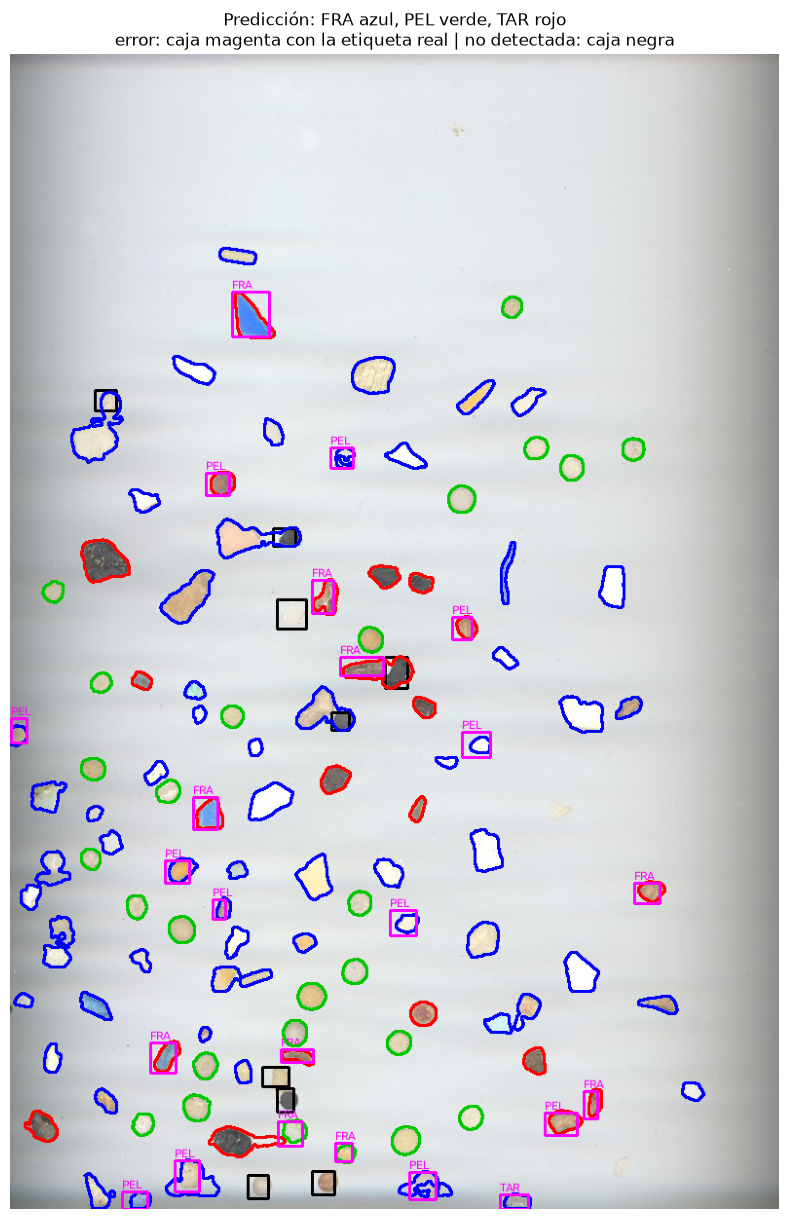

In [17]:
def iou(a, b):
    """IoU entre dos cajas (x_min, y_min, x_max, y_max)."""
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


img_test = cv2.imread('MPs_test.jpg')
contornos_test, feats_test = procesar_imagen(img_test)
umbral_test = umbral_oscuridad(feats_test)
print('Partículas detectadas:', len(contornos_test))
print(f'Umbral de oscuridad (Otsu, test): {umbral_test:.3f}')

cajas_test = []
for c in contornos_test:
    x, y, w, h = cv2.boundingRect(c)
    cajas_test.append((x, y, x + w, y + h))

COLORES = {'FRA': (0, 0, 255), 'PEL': (0, 200, 0), 'TAR': (255, 0, 0)}  # RGB: FRA azul, PEL verde, TAR rojo
vista = cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB)

y_true, y_pred, no_detectadas = [], [], []
with open('MPs_test_bbs.csv', newline='') as f:
    for row in csv.DictReader(f):
        caja_gt = tuple(map(int, [row['x_min'], row['y_min'], row['x_max'], row['y_max']]))

        # Busca el contorno detectado que mejor encaja con la anotación
        ious = [iou(caja_gt, cb) for cb in cajas_test]
        if not ious or max(ious) < 0.3:
            no_detectadas.append(row['label'])
            cv2.rectangle(vista, caja_gt[:2], caja_gt[2:], (0, 0, 0), 2)
            continue
        k = int(np.argmax(ious))
        pred = clasificar(feats_test[k], modelo, umbral_test)
        y_true.append(row['label'])
        y_pred.append(pred)

        # Contorno con el color de la predicción; si es un error, caja magenta con la etiqueta real
        cv2.drawContours(vista, [contornos_test[k]], -1, COLORES[pred], 2)
        if pred != row['label']:
            cv2.rectangle(vista, caja_gt[:2], caja_gt[2:], (255, 0, 255), 2)
            cv2.putText(vista, row['label'], (caja_gt[0], caja_gt[1] - 3),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 255), 1)

print('Partículas evaluadas:', len(y_true), '| No detectadas:', len(no_detectadas), no_detectadas)

plt.figure(figsize=(10, 15))
plt.axis('off')
plt.imshow(vista)
plt.title('Predicción: FRA azul, PEL verde, TAR rojo\n'
          'error: caja magenta con la etiqueta real | no detectada: caja negra')
plt.show()

### 2.5 Métricas y matriz de confusión

Accuracy  = 0.793
Precision = 0.831
Recall    = 0.793
F1 Score  = 0.799

Por clase:
  FRA: precision 0.84  recall 0.84  F1 0.84
  PEL: precision 0.92  recall 0.67  F1 0.77
  TAR: precision 0.50  recall 0.92  F1 0.65


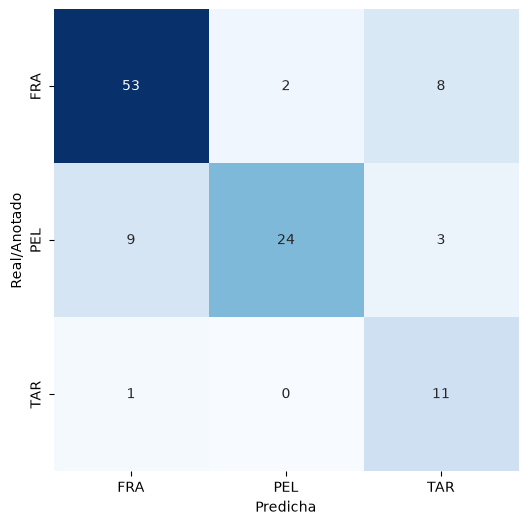

In [18]:
print(f"Accuracy  = {accuracy_score(y_true, y_pred):.3f}")
print(f"Precision = {precision_score(y_true, y_pred, labels=CLASES, average='weighted', zero_division=0):.3f}")
print(f"Recall    = {recall_score(y_true, y_pred, labels=CLASES, average='weighted', zero_division=0):.3f}")
print(f"F1 Score  = {f1_score(y_true, y_pred, labels=CLASES, average='weighted', zero_division=0):.3f}")
print()
print('Por clase:')
for clase, p, r, f1 in zip(CLASES,
                           precision_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0),
                           recall_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0),
                           f1_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)):
    print(f'  {clase}: precision {p:.2f}  recall {r:.2f}  F1 {f1:.2f}')

conf_matrix = confusion_matrix(y_true, y_pred, labels=CLASES)
plt.figure(figsize=(6, 6))
ax = sns.heatmap(conf_matrix, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=CLASES, yticklabels=CLASES)
ax.set_xlabel('Predicha')
ax.set_ylabel('Real/Anotado')
plt.show()

**Conclusiones Tarea 2**

*Resultados.* Sobre las propias partículas de entrenamiento (180) la accuracy es 0.78. En el test se detectan 111 de las 120 partículas anotadas (9 no detectadas), y sobre ellas: **accuracy 0.79, precision 0.83, recall 0.79, F1 0.80** (ponderadas).

| Real \ Predicha | FRA | PEL | TAR |
|---|---|---|---|
| FRA | 53 | 2 | 8 |
| PEL | 9 | 24 | 3 |
| TAR | 1 | 0 | 11 |

*¿Qué clases se confunden más?*
- **PEL → FRA** (9): pellets algo irregulares, aplastados o pegados a otra partícula, cuyo contorno deja de ser redondeado.
- **FRA → TAR** (8): fragmentos marrones o grises oscuros que quedan por debajo del umbral de oscuridad. En el test el umbral de Otsu (0.80) separa las partículas oscuras de las claras, no solo el alquitrán negro.
- El alquitrán se reconoce casi siempre (11 de 12 detectados), pero con precisión baja por los fragmentos oscuros.
- En el entrenamiento la confusión principal es **PEL → TAR** (22): hay pellets marrones bastante oscuros.

*¿Qué características han resultado más útiles?*
- La **oscuridad relativa** para el alquitrán: su mediana es 0.41, frente a 0.63 de los pellets y 0.82 de los fragmentos.
- Para pellets y fragmentos, las de **forma**: relación de distancias al centroide (0.80 frente a 0.54), relación de ejes de la elipse (0.89 frente a 0.71) y compacidad (14.4 frente a 16.4, con una dispersión mucho mayor en los fragmentos).
- El **área** y el **perímetro** no sirven entre imágenes con escalas distintas, y el **color** absoluto tampoco: la cámara y el escáner dan tonos muy diferentes.

*¿Cómo afecta la segmentación?*
- Con un umbral global (fijo u Otsu) sobre el gris se pierden casi todos los fragmentos blancos y transparentes, que apenas se distinguen del fondo. Con `adaptiveThreshold` quedaban 36 partículas del test sin detectar; restando el fondo estimado con la mediana, solo 9.
- Las partículas que se tocan forman un solo contorno, y sus características dejan de ser las de ninguna de las dos. En el borde inferior del test la sombra del escáner se une a algunas partículas.
- Las 9 partículas no detectadas son muy pequeñas o muy claras, o están unidas a otra y el IoU con su caja baja de 0.3.

*Principal dificultad: el cambio de dominio.* El entrenamiento son fotos y el test, un escaneo: escala, iluminación, fondo y curva de tonos son distintos. Un umbral de oscuridad fijo sacado del entrenamiento no reconocía casi ningún alquitrán del test, porque el escáner aclara los negros (el alquitrán pasa de un gris de 16 sobre un fondo de 122 a 90 sobre 220). Calcular ese umbral en cada imagen con Otsu lo resuelve sin usar las anotaciones del test. Este problema se detectó al evaluar en el test.